In [ ]:
#imports
import numpy as np
from amuse.lab import *
from amuse.ext.orbital_elements import new_binary_from_orbital_elements
from amuse.community.ph4.interface import Ph4
from matplotlib import pyplot as plt

In [ ]:
def initial_conditions():

    msun= 1 | units.MSun
    msaturn= 0.00028 | units.MSun
    a_saturn= 9.5 | units.au
    e_saturn= 0.05

    bodies= new_binary_from_orbital_elements(msun, msaturn, a_saturn, e_saturn)
    bodies.name= ["sun", "saturn"]

    mjapetus= 1.8e+21 | units.kg
    a_japetus= 3.5617e+6 | units.km
    e_japetus= 0.028

    jbinary = new_binary_from_orbital_elements(msaturn, mjapetus, a_japetus, e_japetus)
    jbinary.name = ["fake_saturn_do_not_use_ever", "japetus"]

    saturn_pos = jbinary[0].position.copy()
    saturn_vel = jbinary[0].velocity.copy()

    jbinary.position -= saturn_pos
    jbinary.velocity -= saturn_vel

    japetus = jbinary[jbinary.name == "japetus"]
    saturn = bodies[bodies.name == "saturn"]

    japetus.position += saturn.position
    japetus.velocity += saturn.velocity

    bodies.add_particles(japetus)
    bodies.radius = 0 | units.km

    return bodies

In [ ]:
def make_ring(iapetus, N=100):

    ring = Particles(N)

    r= np.random.uniform(1000, 1800, N) | units.km
    theta= np.random.uniform(0, 2*np.pi, N)
    ring.mass= 0 | units.kg
    ring.x= iapetus.x + r * np.cos(theta)
    ring.y= iapetus.y + r * np.sin(theta)
    ring.z= iapetus.z

    v= (constants.G * iapetus.mass / r).sqrt()

    ring.vx= iapetus.vx - v * np.sin(theta)
    ring.vy= iapetus.vy + v * np.cos(theta)
    ring.vz= iapetus.vz

    return ring

/Users/ankitadasgupta/miniconda3/envs/Amuse-env/lib/python3.13/site-packages/amuse/ext/orbital_elements.py:344: UserWarning: new_binary_from_orbital_elements is deprecated, use generate_binaries instead
  warnings.warn(


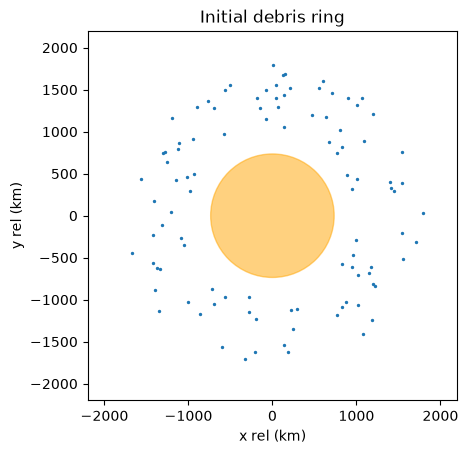

In [ ]:
#sim setup and initial point plot
bodies= initial_conditions()
iapetus= bodies[bodies.name == "japetus"]
ring= make_ring(iapetus)

end_time= 2 | units.day

#plot the initial debris ring around Iapetus
plt.figure()

plt.scatter((ring.x - iapetus.x).value_in(units.km),(ring.y - iapetus.y).value_in(units.km),s=2)

#wanted to make iapetus it's comparable size-ish
plt.gca().add_patch(plt.Circle((0, 0), 735, color="orange", alpha=0.5))

plt.xlim(-2200, 2200)
plt.ylim(-2200, 2200)
plt.gca().set_aspect("equal")
#relative axes to iapetus
plt.xlabel("x rel (km)")
plt.ylabel("y rel (km)")
plt.title("Initial debris ring")
plt.show()

In [ ]:
converter= nbody_system.nbody_to_si(bodies.mass.sum(), 1 | units.au)

gravity= Ph4(converter)
gravity.parameters.timestep_parameter= 0.01

#adding massive bodies and debris
gravity.particles.add_particles(bodies)
gravity.particles.add_particles(ring)

#updating particle pos and vel
channel_bodies= gravity.particles.new_channel_to(bodies)
channel_ring= gravity.particles.new_channel_to(ring)

gravity.evolve_model(end_time)
gravity.synchronize_model()

channel_bodies.copy()
channel_ring.copy()

print("Simulation time:", gravity.model_time.in_(units.hour))

gravity.stop()

Simulation time: 48.00393694 hr


In [22]:
#final debris distances
distance = ((ring.x - iapetus.x)**2 + (ring.y - iapetus.y)**2 + (ring.z - iapetus.z)**2).sqrt()

print("Number of particles:", len(ring))
print("Minimum distance:", distance.min().in_(units.km))
print("Maximum distance:", distance.max().in_(units.km))
print("Particles inside Iapetus:", (distance < (735 | units.km)).sum())

Number of particles: 100
Minimum distance: 1000.60908209 km
Maximum distance: 1792.8427168 km
Particles inside Iapetus: 0


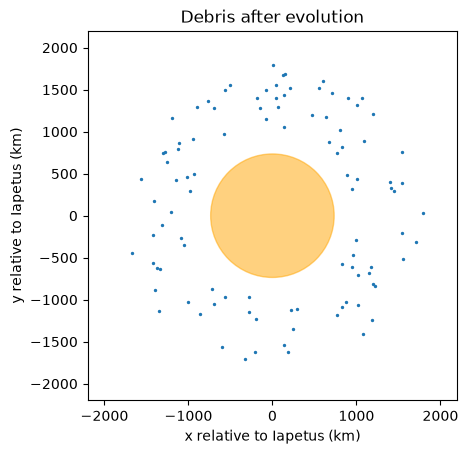

In [23]:
#plot post evolution
plt.figure()

plt.scatter((ring.x - iapetus.x).value_in(units.km),(ring.y - iapetus.y).value_in(units.km),s=2)

plt.gca().add_patch( plt.Circle((0, 0), 735, color="orange", alpha=0.5))

plt.xlim(-2200, 2200)
plt.ylim(-2200, 2200)
plt.gca().set_aspect("equal")
plt.xlabel("x relative to Iapetus (km)")
plt.ylabel("y relative to Iapetus (km)")
plt.title("Debris after evolution")
plt.show()